# Marketing Mix Media Optimizer — Full Walkthrough

This notebook demonstrates the complete Marketing Mix Model pipeline:

1. **Data generation & EDA** — synthetic marketing time series
2. **Adstock & saturation transforms** — visualising carryover and diminishing returns
3. **Bayesian model fitting & diagnostics** — posterior sampling with PyMC, R-hat, fitted vs actual
4. **Channel attribution & ROI** — contributions with 90% credible intervals
5. **Budget optimisation** — finding the optimal allocation over the posterior
6. **LLM insight generation** — Claude API integration

---

In [5]:
import os
import sys
sys.path.append(os.path.abspath('..')) # Run this from the root directory
sys.path.insert(0, '../..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

plt.style.use('dark_background')
plt.rcParams.update({
    'figure.facecolor': '#0F0F0F',
    'axes.facecolor': '#0F0F0F',
    'axes.edgecolor': '#333',
    'axes.labelcolor': '#CCC',
    'xtick.color': '#888',
    'ytick.color': '#888',
    'grid.color': '#1A1A1A',
    'grid.linewidth': 0.8,
    'font.family': 'monospace',
    'figure.dpi': 120
})

ACCENT_COLORS = ['#C8F060', '#60C8F0', '#F0A060', '#F06090', '#A060F0']
print('✓ Imports ready')

✓ Imports ready


## 1. Data Generation & Exploratory Analysis

In [6]:
from src.data_generator import generate_marketing_data

df = generate_marketing_data(n_weeks=156, seed=42)
channels = ['tv_spend', 'digital_spend', 'social_spend', 'ooh_spend', 'radio_spend']
print(f'Dataset shape: {df.shape}')
print(f'Date range: {df.week.min().date()} → {df.week.max().date()}')
print(f'\nRevenue stats:')
print(df['revenue'].describe().apply(lambda x: f'£{x:,.0f}'))

Dataset shape: (156, 9)
Date range: 2021-01-04 → 2023-12-25

Revenue stats:
count          £156
mean     £1,307,205
std         £91,121
min      £1,115,558
25%      £1,242,439
50%      £1,300,359
75%      £1,372,108
max      £1,528,821
Name: revenue, dtype: str


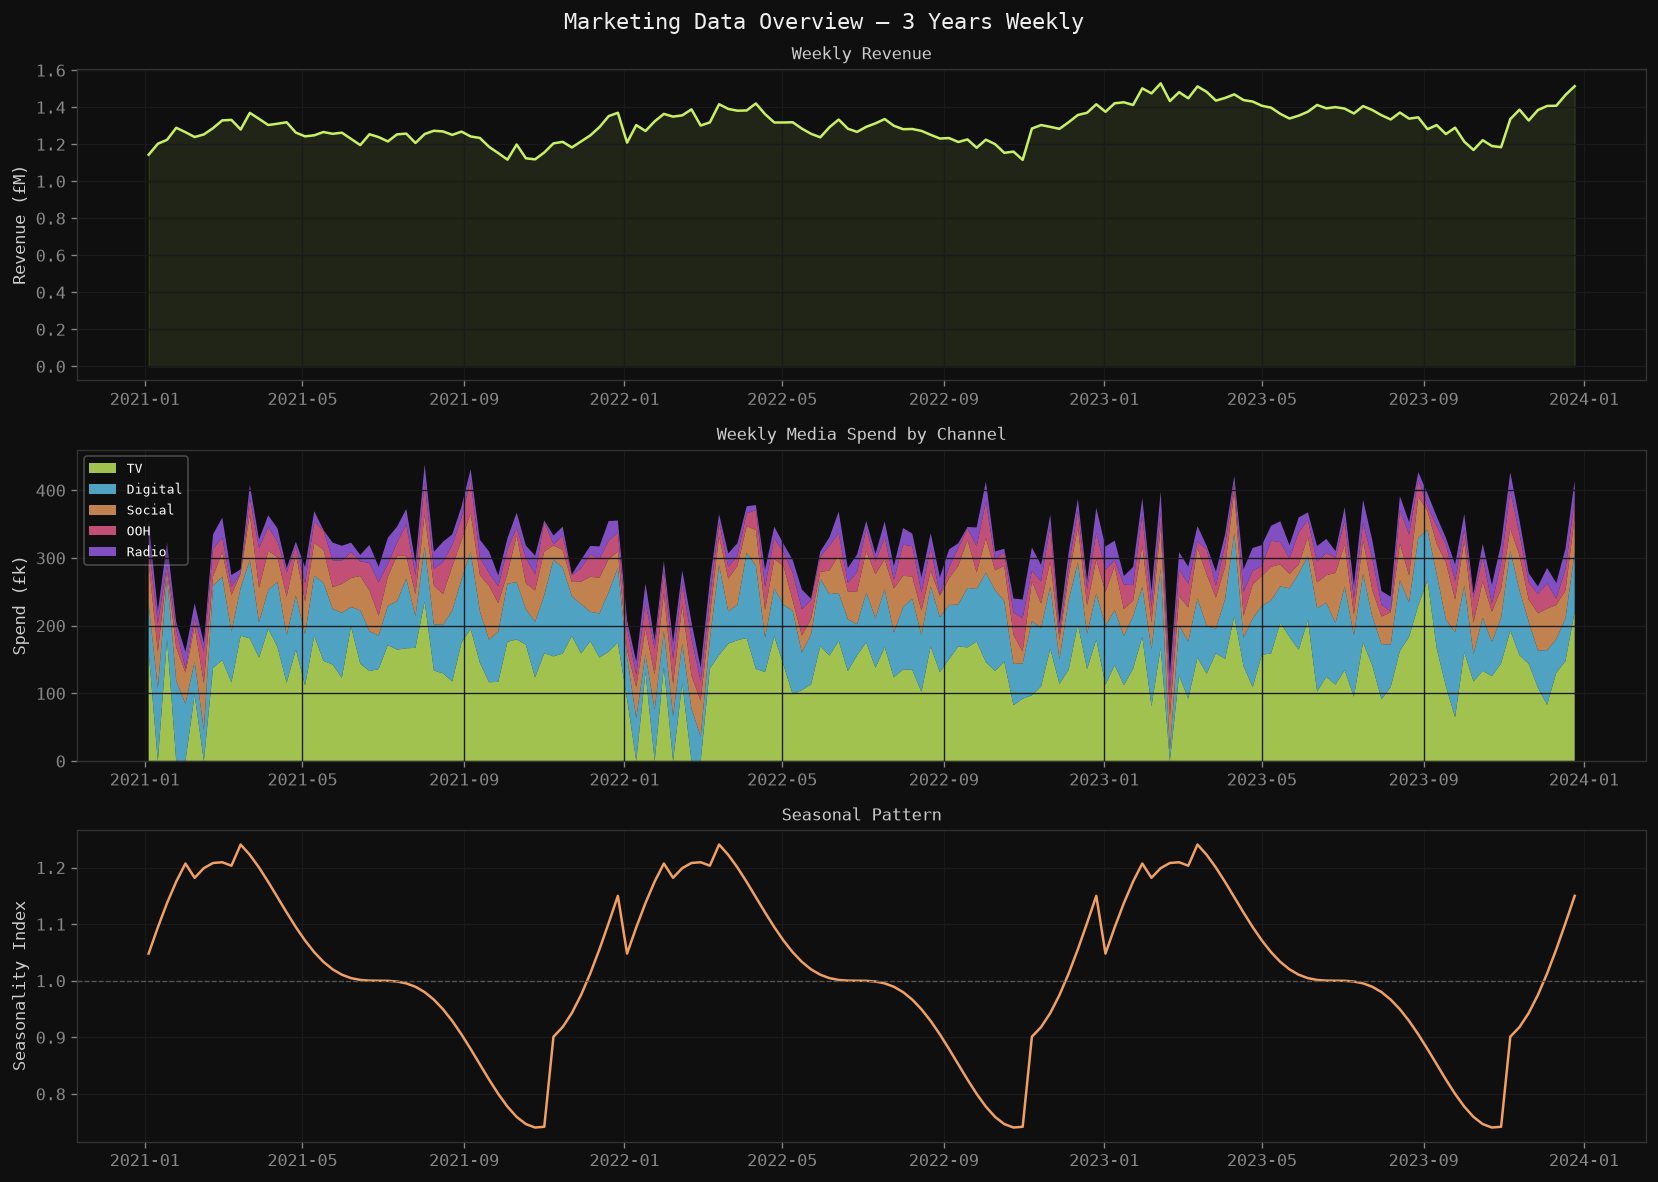

In [7]:
channels = ['tv_spend', 'digital_spend', 'social_spend', 'ooh_spend', 'radio_spend']
channel_labels = ['TV', 'Digital', 'Social', 'OOH', 'Radio']

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle('Marketing Data Overview — 3 Years Weekly', color='#EEE', fontsize=13, y=0.98)

# Revenue
axes[0].plot(df['week'], df['revenue'] / 1e6, color='#C8F060', linewidth=1.5)
axes[0].fill_between(df['week'], df['revenue'] / 1e6, alpha=0.1, color='#C8F060')
axes[0].set_ylabel('Revenue (£M)', color='#CCC')
axes[0].set_title('Weekly Revenue', color='#CCC', fontsize=10)
axes[0].grid(True)

# Stacked media spend
spend_data = [df[ch].values / 1e3 for ch in channels]
axes[1].stackplot(df['week'], spend_data, labels=channel_labels,
                  colors=ACCENT_COLORS, alpha=0.8)
axes[1].set_ylabel('Spend (£k)', color='#CCC')
axes[1].set_title('Weekly Media Spend by Channel', color='#CCC', fontsize=10)
axes[1].legend(loc='upper left', fontsize=8, framealpha=0.3)
axes[1].grid(True)

# Seasonality
axes[2].plot(df['week'], df['seasonality'], color='#F0A060', linewidth=1.5)
axes[2].axhline(1.0, color='#555', linestyle='--', linewidth=0.8)
axes[2].set_ylabel('Seasonality Index', color='#CCC')
axes[2].set_title('Seasonal Pattern', color='#CCC', fontsize=10)
axes[2].grid(True)

plt.tight_layout()
plt.show()

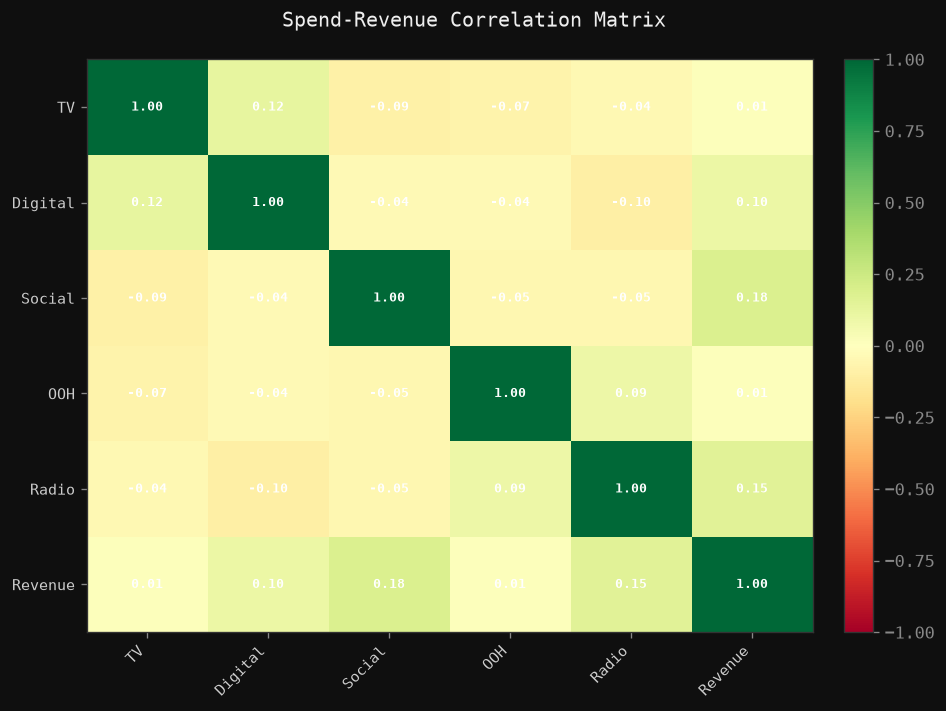

Revenue correlations:
  TV        : r = 0.008
  Digital   : r = 0.101
  Social    : r = 0.185
  OOH       : r = 0.015
  Radio     : r = 0.155


In [8]:
# Correlation heatmap: spend channels vs revenue
corr_cols = channels + ['revenue']
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
fig.suptitle('Spend-Revenue Correlation Matrix', color='#EEE', fontsize=12)

im = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

labels = channel_labels + ['Revenue']
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right', color='#CCC', fontsize=9)
ax.set_yticklabels(labels, color='#CCC', fontsize=9)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center',
                color='white', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

print('Revenue correlations:')
for ch, label in zip(channels, channel_labels):
    print(f'  {label:10s}: r = {df[ch].corr(df["revenue"]):.3f}')

## 2. Adstock & Saturation Transforms

Before fitting the model, let's visualise what the two core transforms actually do.

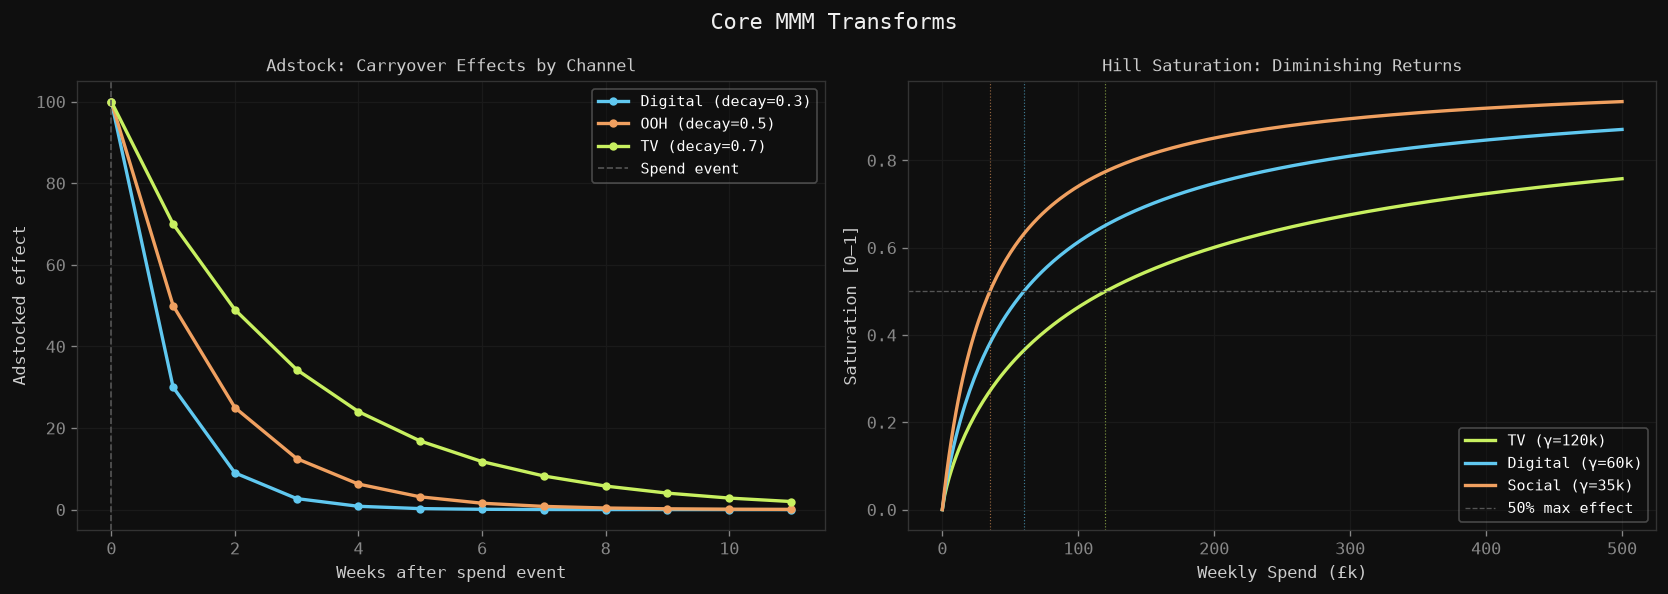

Dotted vertical lines mark each channel's half-saturation point (γ)


In [9]:
from src.mmm_model import adstock_transform, hill_saturation

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Core MMM Transforms', color='#EEE', fontsize=13)

# --- Adstock ---
# Single pulse: spend 100 in week 0, then 0
x_pulse = np.zeros(12); x_pulse[0] = 100
weeks = np.arange(12)

for decay, color, label in [
    (0.3, '#60C8F0', 'Digital (decay=0.3)'),
    (0.5, '#F0A060', 'OOH (decay=0.5)'),
    (0.7, '#C8F060', 'TV (decay=0.7)'),
]:
    adstocked = adstock_transform(x_pulse, decay)
    axes[0].plot(weeks, adstocked, color=color, linewidth=2, label=label, marker='o', markersize=4)

axes[0].axvline(0, color='#555', linestyle='--', linewidth=1, label='Spend event')
axes[0].set_xlabel('Weeks after spend event', color='#CCC')
axes[0].set_ylabel('Adstocked effect', color='#CCC')
axes[0].set_title('Adstock: Carryover Effects by Channel', color='#CCC', fontsize=10)
axes[0].legend(fontsize=9, framealpha=0.3)
axes[0].grid(True)

# --- Hill Saturation ---
spend_range = np.linspace(0, 500_000, 300)

for gamma, alpha, color, label in [
    (120_000, 0.8, '#C8F060', 'TV (γ=120k)'),
    (60_000,  0.9, '#60C8F0', 'Digital (γ=60k)'),
    (35_000,  1.0, '#F0A060', 'Social (γ=35k)'),
]:
    sat = hill_saturation(spend_range, alpha, gamma)
    axes[1].plot(spend_range / 1e3, sat, color=color, linewidth=2, label=label)
    # Mark half-saturation point
    axes[1].axvline(gamma / 1e3, color=color, linewidth=0.7, linestyle=':', alpha=0.6)

axes[1].axhline(0.5, color='#555', linestyle='--', linewidth=0.8, label='50% max effect')
axes[1].set_xlabel('Weekly Spend (£k)', color='#CCC')
axes[1].set_ylabel('Saturation [0–1]', color='#CCC')
axes[1].set_title('Hill Saturation: Diminishing Returns', color='#CCC', fontsize=10)
axes[1].legend(fontsize=9, framealpha=0.3)
axes[1].grid(True)

plt.tight_layout()
plt.show()
print('Dotted vertical lines mark each channel\'s half-saturation point (γ)')

## 3. Model Fitting & Diagnostics

In [10]:
from src.mmm_model import MarketingMixModel
from sklearn.metrics import r2_score

# Train on first 2.5 years, hold out last 26 weeks
train_df = df.iloc[:130].reset_index(drop=True)
test_df  = df.iloc[130:].reset_index(drop=True)

# Samples the posterior with NUTS (PyMC). Expect a few minutes on a laptop.
model = MarketingMixModel(channels=channels, target='revenue')
model.fit(train_df, draws=1000, tune=1000, chains=4)

print('Sampler diagnostics:', model.diagnostics_)

train_preds = model.predict(train_df)
test_preds  = model.predict(test_df)

train_r2 = r2_score(train_df['revenue'], train_preds)
test_r2  = r2_score(test_df['revenue'], test_preds)

print(f'Train R²:    {train_r2:.4f}')
print(f'Test R²:     {test_r2:.4f}  ← holdout')
print(f'Train MAPE:  {model.train_mape_*100:.1f}%')

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [decay, alpha, gamma, beta, intercept, sigma, control_coef]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2534 seconds.
There were 24 divergences after tuning. Increase `target_accept` or reparameterize.


Sampler diagnostics: {'max_rhat': 1.0015534362484482, 'divergences': 24, 'chains': 4, 'draws_per_chain': 1000}
Train R²:    0.9760
Test R²:     0.8644  ← holdout
Train MAPE:  0.9%


### Posterior summary

Each parameter now has a distribution, not a single value. `r_hat` close to 1.00 means the chains agree; values above about 1.01 or any divergences mean the sampler needs more tuning steps or a higher `target_accept`.

In [11]:
import arviz as az

az.summary(model.idata_, var_names=['decay', 'alpha', 'gamma', 'beta', 'sigma'], round_to=3)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
decay[tv_spend],0.624,0.073,0.488,0.754,0.001,0.002,5352.520,2873.804,1.000
decay[digital_spend],0.405,0.049,0.316,0.499,0.001,0.001,4989.259,3161.640,1.000
decay[social_spend],0.178,0.051,0.083,0.269,0.001,0.001,5922.640,2388.692,1.000
decay[ooh_spend],0.477,0.119,0.239,0.679,0.002,0.002,5637.481,2517.577,1.001
decay[radio_spend],0.539,0.130,0.293,0.763,0.002,0.002,4327.400,2326.526,1.001
alpha[tv_spend],0.653,0.348,0.128,1.275,0.005,0.007,3876.014,2988.554,1.001
alpha[digital_spend],0.881,0.421,0.243,1.655,0.007,0.008,3093.628,3010.877,1.002
alpha[social_spend],0.685,0.343,0.167,1.311,0.006,0.006,3025.144,2890.817,1.002
alpha[ooh_spend],0.774,0.504,0.089,1.709,0.008,0.009,3528.795,2385.264,1.002
alpha[radio_spend],0.791,0.486,0.092,1.649,0.008,0.010,3123.036,2750.753,1.000


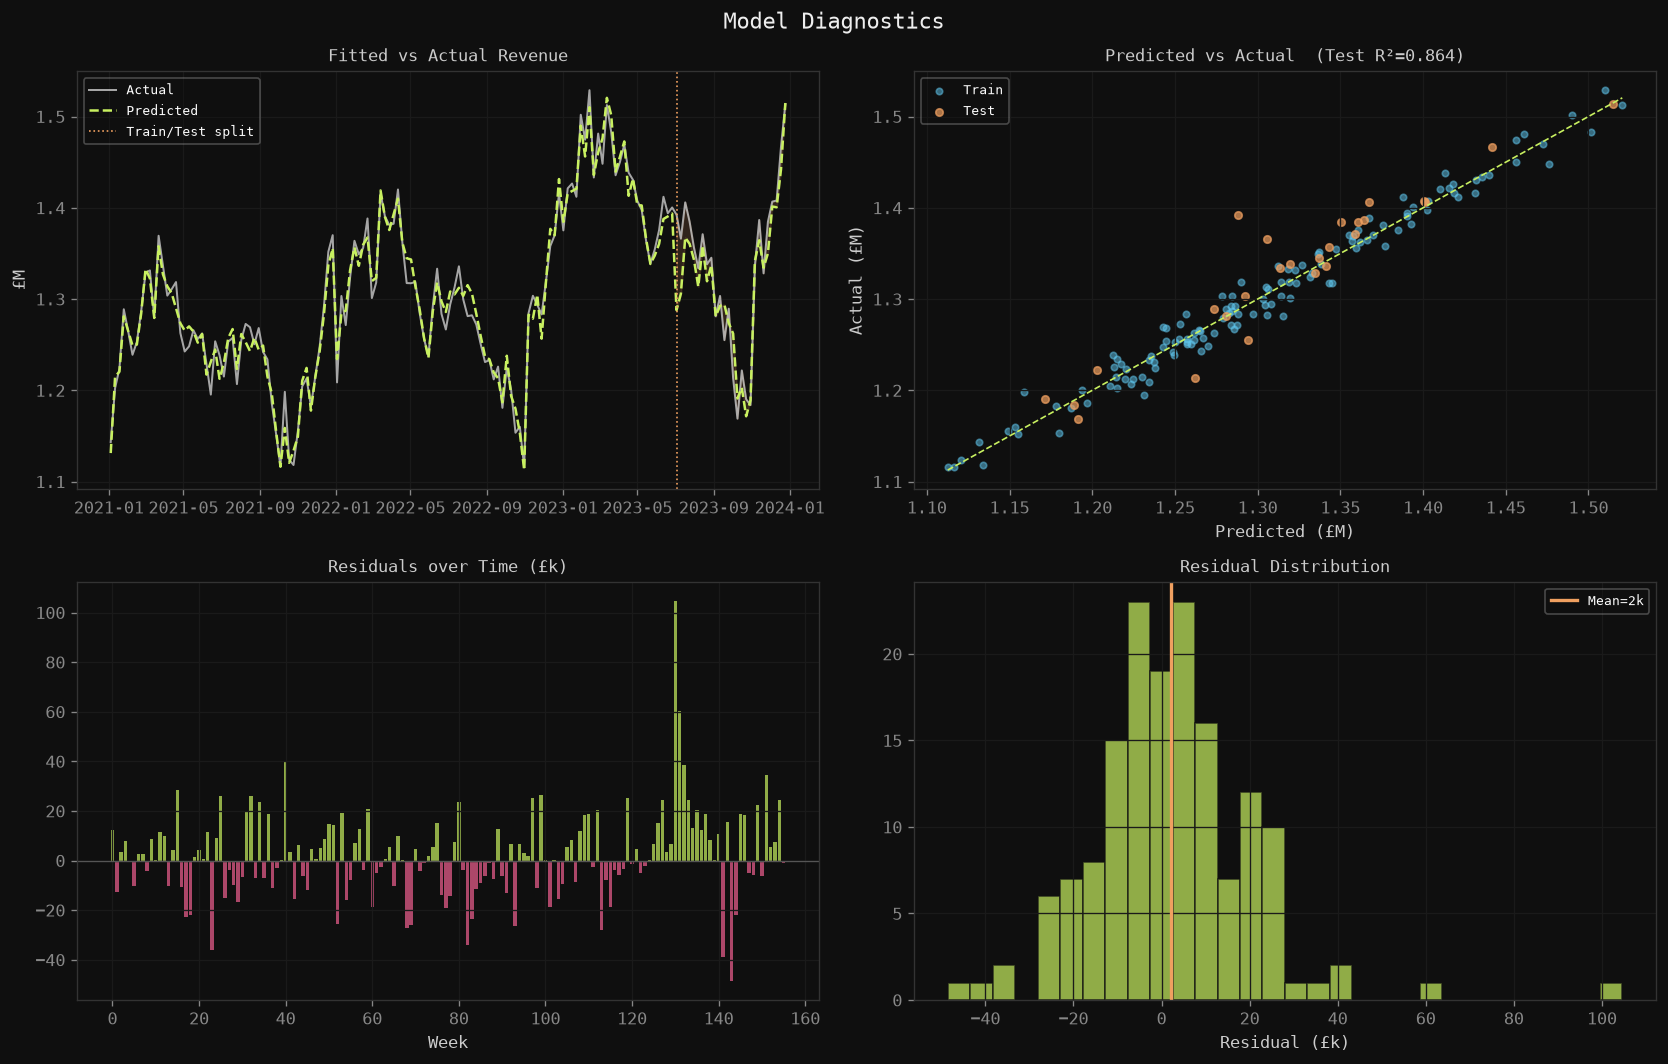

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Model Diagnostics', color='#EEE', fontsize=13)

all_preds = np.concatenate([train_preds, test_preds])
all_actual = df['revenue'].values

# 1. Fitted vs Actual over time
axes[0,0].plot(df['week'], all_actual / 1e6, color='#CCC', linewidth=1.2, label='Actual', alpha=0.8)
axes[0,0].plot(df['week'], all_preds / 1e6, color='#C8F060', linewidth=1.5, label='Predicted', linestyle='--')
axes[0,0].axvline(df['week'].iloc[130], color='#F0A060', linewidth=1, linestyle=':', label='Train/Test split')
axes[0,0].fill_between(df['week'].iloc[130:], test_preds/1e6, test_df['revenue'].values/1e6,
                        alpha=0.15, color='#F0A060')
axes[0,0].set_title('Fitted vs Actual Revenue', color='#CCC', fontsize=10)
axes[0,0].set_ylabel('£M', color='#CCC')
axes[0,0].legend(fontsize=8, framealpha=0.3)
axes[0,0].grid(True)

# 2. Scatter: predicted vs actual
axes[0,1].scatter(train_preds/1e6, train_df['revenue'].values/1e6,
                  color='#60C8F0', alpha=0.5, s=15, label='Train')
axes[0,1].scatter(test_preds/1e6, test_df['revenue'].values/1e6,
                  color='#F0A060', alpha=0.7, s=20, label='Test')
mn, mx = all_preds.min()/1e6, all_preds.max()/1e6
axes[0,1].plot([mn, mx], [mn, mx], color='#C8F060', linewidth=1, linestyle='--')
axes[0,1].set_xlabel('Predicted (£M)', color='#CCC')
axes[0,1].set_ylabel('Actual (£M)', color='#CCC')
axes[0,1].set_title(f'Predicted vs Actual  (Test R²={test_r2:.3f})', color='#CCC', fontsize=10)
axes[0,1].legend(fontsize=8, framealpha=0.3)
axes[0,1].grid(True)

# 3. Residuals over time
residuals = (all_actual - all_preds) / 1e3
axes[1,0].bar(range(len(residuals)), residuals,
              color=['#C8F060' if r >= 0 else '#F06090' for r in residuals],
              alpha=0.7, width=0.8)
axes[1,0].axhline(0, color='#555', linewidth=0.8)
axes[1,0].set_title('Residuals over Time (£k)', color='#CCC', fontsize=10)
axes[1,0].set_xlabel('Week', color='#CCC')
axes[1,0].grid(True)

# 4. Residual distribution
axes[1,1].hist(residuals, bins=30, color='#C8F060', alpha=0.7, edgecolor='#0F0F0F')
axes[1,1].axvline(residuals.mean(), color='#F0A060', linewidth=2, label=f'Mean={residuals.mean():.0f}k')
axes[1,1].set_title('Residual Distribution', color='#CCC', fontsize=10)
axes[1,1].set_xlabel('Residual (£k)', color='#CCC')
axes[1,1].legend(fontsize=8, framealpha=0.3)
axes[1,1].grid(True)

plt.tight_layout()
plt.show()

## 4. Channel Attribution — Revenue Decomposition

In [13]:
contrib = model.channel_contribution(train_df)
print('Channel Revenue Attribution:')
print(contrib.to_string(index=False))

Channel Revenue Attribution:
      channel  contribution  contribution_lower  contribution_upper  contribution_pct
digital_spend  3.374654e+07        1.230669e+07        6.721803e+07         30.573065
 social_spend  2.721141e+07        1.094762e+07        5.463414e+07         24.652488
     tv_spend  2.221388e+07        8.518217e+06        4.615784e+07         20.124923
  radio_spend  1.462960e+07        3.634087e+06        3.697518e+07         13.253856
    ooh_spend  1.257853e+07        2.823685e+06        3.340572e+07         11.395667


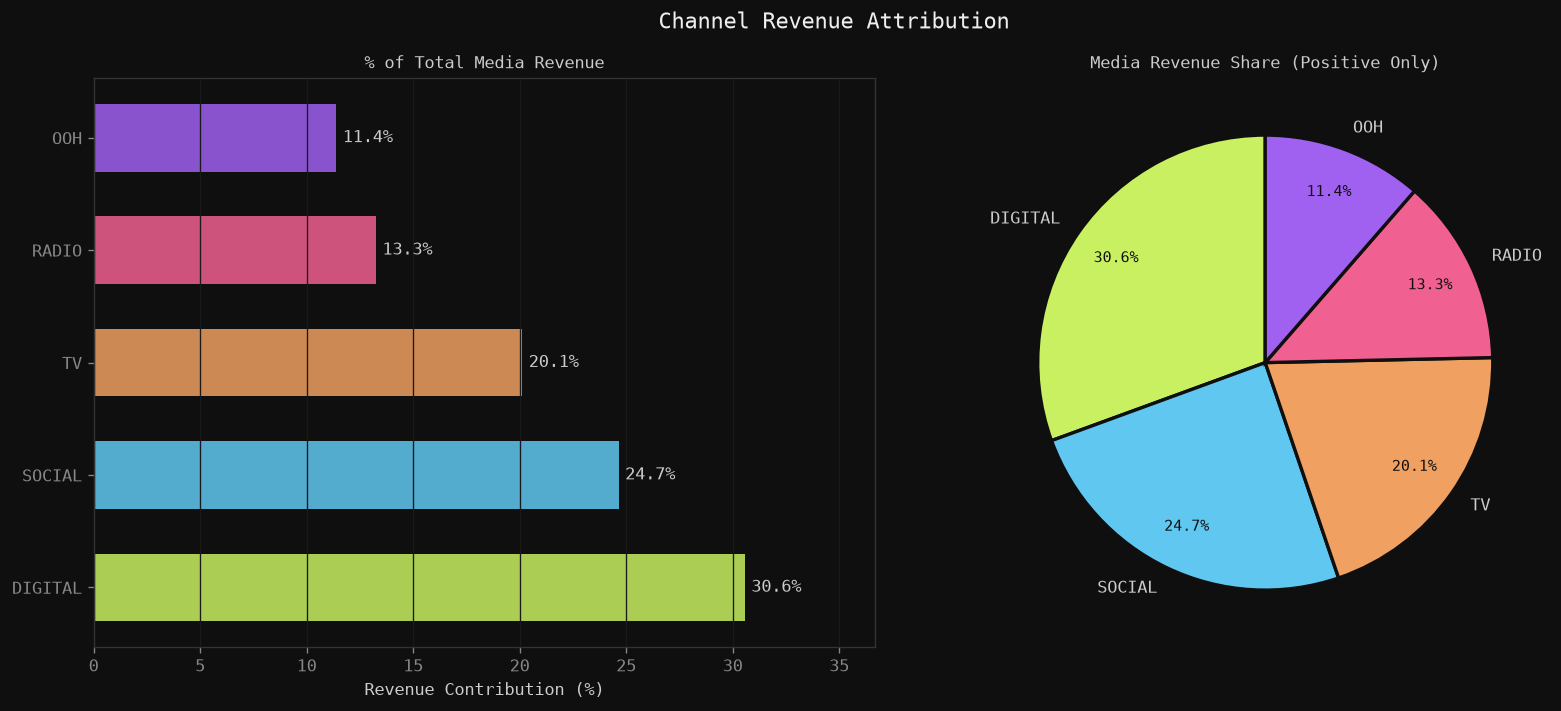

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Channel Revenue Attribution', color='#EEE', fontsize=13)

ch_labels = [c.replace('_spend', '').upper() for c in contrib['channel']]
contribs = contrib['contribution_pct'].values

# Horizontal bar chart
bars = axes[0].barh(ch_labels, contribs, color=ACCENT_COLORS[:len(ch_labels)], alpha=0.85, height=0.6)
for bar, val in zip(bars, contribs):
    axes[0].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', color='#CCC', fontsize=10)
axes[0].set_xlabel('Revenue Contribution (%)', color='#CCC')
axes[0].set_title('% of Total Media Revenue', color='#CCC', fontsize=10)
axes[0].set_xlim(0, max(contribs) * 1.2)
axes[0].grid(True, axis='x')

# Pie chart - only positive contributions
positive_contrib = contrib[contrib['contribution_pct'] > 0]
pie_labels = [c.replace('_spend', '').upper() for c in positive_contrib['channel']]
pie_contribs = positive_contrib['contribution_pct'].values
pie_colors = ACCENT_COLORS[:len(pie_labels)]

wedges, texts, autotexts = axes[1].pie(
    pie_contribs, labels=pie_labels, autopct='%1.1f%%',
    colors=pie_colors,
    startangle=90, pctdistance=0.8,
    wedgeprops={'edgecolor': '#0F0F0F', 'linewidth': 2}
)
for text in texts: text.set_color('#CCC')
for autotext in autotexts: autotext.set_color('#0F0F0F'); autotext.set_fontsize(9)
axes[1].set_title('Media Revenue Share (Positive Only)', color='#CCC', fontsize=10)

plt.tight_layout()
plt.show()

### ROI by channel, with uncertainty

ROI is revenue attributed to the channel divided by what was spent on it. The bars show the 90% credible interval, and `prob_roi_above_1` is the posterior probability that the channel returned more than it cost.

      channel       spend  roi  roi_lower  roi_upper  prob_roi_above_1
  radio_spend  2563088.99 5.71       1.42      14.43              0.99
 social_spend  5816609.12 4.68       1.88       9.39              1.00
    ooh_spend  3708273.26 3.39       0.76       9.01              0.90
digital_spend 10422007.30 3.24       1.18       6.45              0.98
     tv_spend 17810000.33 1.25       0.48       2.59              0.56


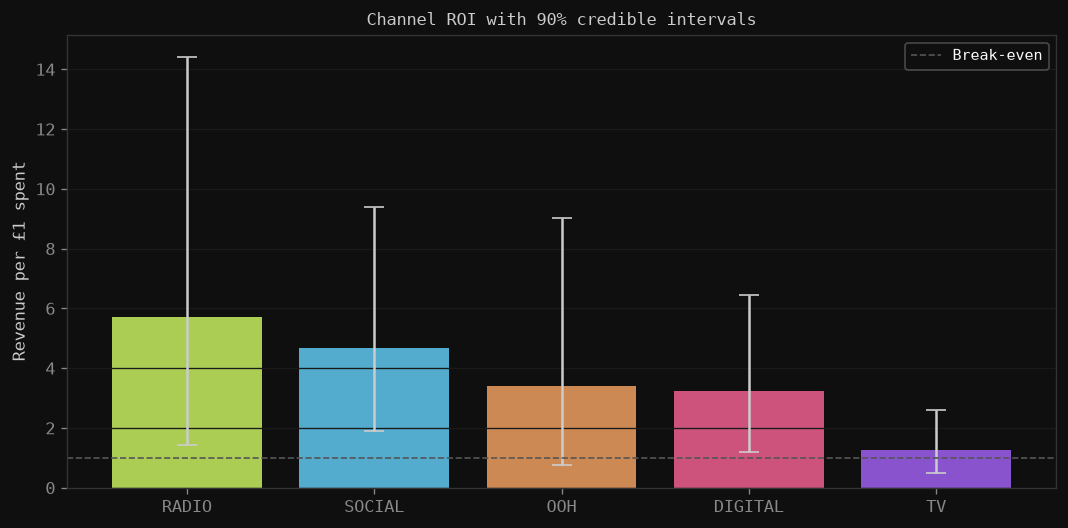

In [15]:
roi = model.channel_roi(train_df)
print(roi.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [c.replace('_spend', '').upper() for c in roi['channel']]
errors = [roi['roi'] - roi['roi_lower'], roi['roi_upper'] - roi['roi']]
ax.bar(labels, roi['roi'], yerr=errors, color=ACCENT_COLORS[:len(labels)], alpha=0.85,
       capsize=6, ecolor='#CCC')
ax.axhline(1.0, color='#555', linestyle='--', linewidth=1, label='Break-even')
ax.set_ylabel('Revenue per £1 spent', color='#CCC')
ax.set_title('Channel ROI with 90% credible intervals', color='#CCC', fontsize=10)
ax.legend(fontsize=9, framealpha=0.3)
ax.grid(True, axis='y')
plt.tight_layout()
plt.show()

## 5. Budget Optimisation

In [16]:
total_budget = 17_000_000  # £17M annual budget
result = model.optimise_budget(total_budget, train_df, n_weeks=52)

print(f"Expected Annual Revenue: £{result['expected_revenue']:,.0f}")
low, high = result['expected_revenue_interval']
print(f"90% credible interval:   £{low:,.0f} to £{high:,.0f}")
print(f"Expected uplift vs current mix: £{result['expected_uplift']:,.0f} "
      f"(probability of beating the current mix: {result['prob_better_than_current_mix']:.0%})")
print(f"\nOptimal Allocation:")
for ch, budget in result['optimal_allocation'].items():
    label = ch.replace('_spend', '').upper()
    roi = result['roi_by_channel'][ch]
    print(f"  {label:10s}  £{budget:>10,.0f}  (ROI: {roi:.2f}x)")

Expected Annual Revenue: £67,738,106
90% credible interval:   £66,982,596 to £68,540,042
Expected uplift vs current mix: £2,146,794 (probability of beating the current mix: 100%)

Optimal Allocation:
  TV          £ 2,817,720  (ROI: 2.83x)
  DIGITAL     £ 6,660,702  (ROI: 2.38x)
  SOCIAL      £ 3,622,698  (ROI: 3.30x)
  OOH         £ 1,834,355  (ROI: 3.06x)
  RADIO       £ 2,064,525  (ROI: 3.45x)


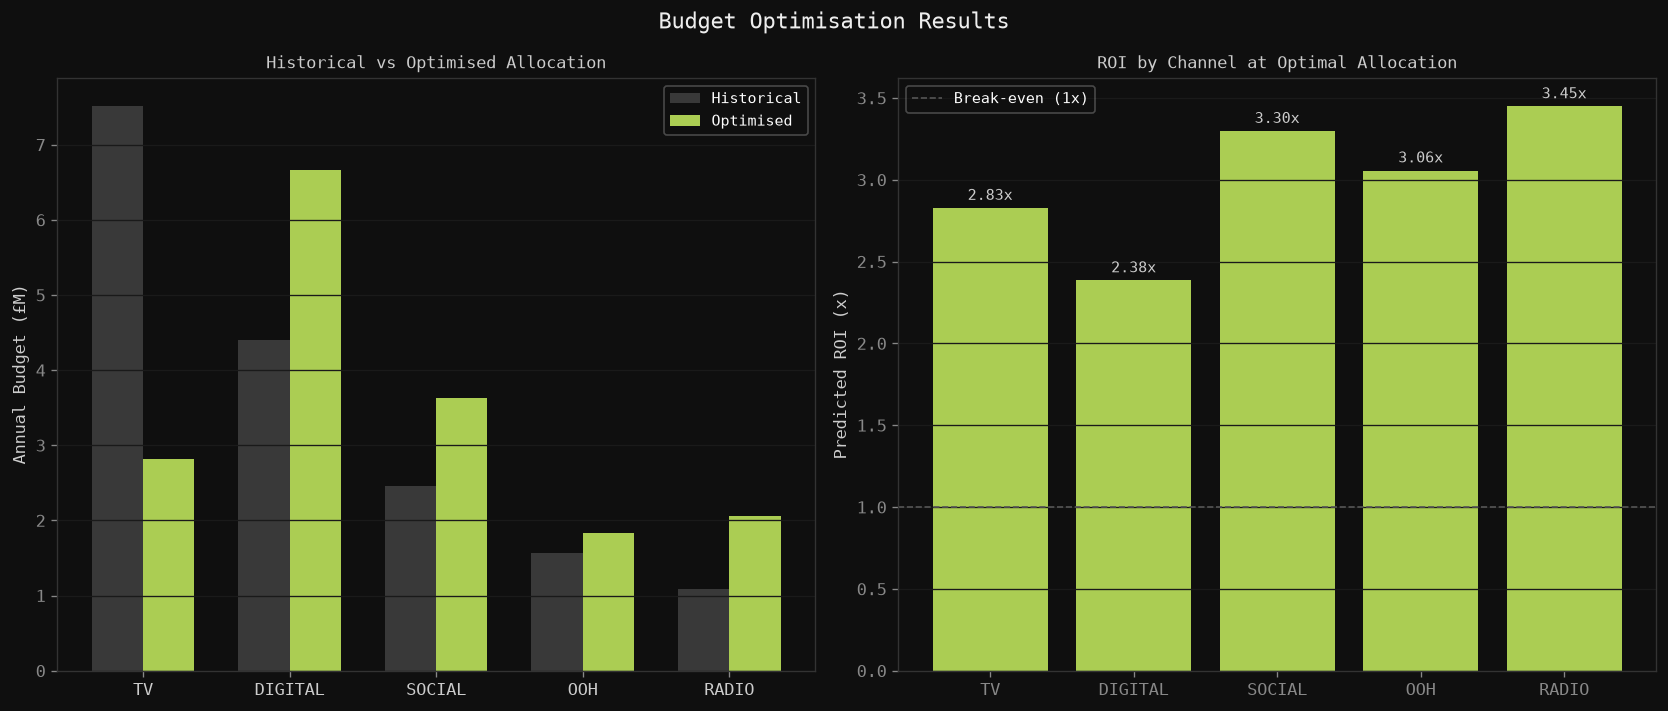

In [17]:
# Historical vs Optimised allocation comparison
historical = {ch: train_df[ch].sum() for ch in channels}
hist_total = sum(historical.values())
hist_scaled = {k: v / hist_total * total_budget for k, v in historical.items()}

ch_labels_short = [c.replace('_spend', '').upper() for c in channels]
x = np.arange(len(channels))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Budget Optimisation Results', color='#EEE', fontsize=13)

# Grouped bar: historical vs optimal
hist_vals = [hist_scaled[ch] / 1e6 for ch in channels]
opt_vals  = [result['optimal_allocation'][ch] / 1e6 for ch in channels]

bars1 = axes[0].bar(x - width/2, hist_vals, width, label='Historical', color='#444', alpha=0.8)
bars2 = axes[0].bar(x + width/2, opt_vals, width, label='Optimised', color='#C8F060', alpha=0.85)

axes[0].set_xticks(x)
axes[0].set_xticklabels(ch_labels_short, color='#CCC')
axes[0].set_ylabel('Annual Budget (£M)', color='#CCC')
axes[0].set_title('Historical vs Optimised Allocation', color='#CCC', fontsize=10)
axes[0].legend(fontsize=9, framealpha=0.3)
axes[0].grid(True, axis='y')

# ROI by channel
roi_vals = [result['roi_by_channel'][ch] for ch in channels]
bar_colors = ['#C8F060' if r >= 2 else '#F0A060' if r >= 1.5 else '#F06090' for r in roi_vals]
axes[1].bar(ch_labels_short, roi_vals, color=bar_colors, alpha=0.85)
axes[1].axhline(1.0, color='#555', linestyle='--', linewidth=1, label='Break-even (1x)')
axes[1].set_ylabel('Predicted ROI (x)', color='#CCC')
axes[1].set_title('ROI by Channel at Optimal Allocation', color='#CCC', fontsize=10)
axes[1].legend(fontsize=9, framealpha=0.3)
axes[1].grid(True, axis='y')
for i, (label, val) in enumerate(zip(ch_labels_short, roi_vals)):
    axes[1].text(i, val + 0.05, f'{val:.2f}x', ha='center', color='#CCC', fontsize=9)

plt.tight_layout()
plt.show()

## 6. LLM Insight Generation

In [18]:
from src.llm_insights import generate_llm_insights
from IPython.display import Markdown

# Generate structured payload
payload = model.generate_insight_payload(train_df, total_budget)
print('Insight payload (structured JSON passed to LLM):')
import json
print(json.dumps(payload, indent=2, default=str))

Insight payload (structured JSON passed to LLM):
{
  "model_performance": {
    "r2_score": 0.976,
    "mape_pct": 0.85
  },
  "sampler_diagnostics": {
    "max_rhat": 1.0015534362484482,
    "divergences": 24,
    "chains": 4,
    "draws_per_chain": 1000
  },
  "credible_interval_pct": 90,
  "channel_attribution": [
    {
      "channel": "digital_spend",
      "contribution": 33746540.64,
      "contribution_lower": 12306685.18,
      "contribution_upper": 67218032.56,
      "contribution_pct": 30.57
    },
    {
      "channel": "social_spend",
      "contribution": 27211409.57,
      "contribution_lower": 10947621.64,
      "contribution_upper": 54634142.81,
      "contribution_pct": 24.65
    },
    {
      "channel": "tv_spend",
      "contribution": 22213884.1,
      "contribution_lower": 8518216.94,
      "contribution_upper": 46157838.96,
      "contribution_pct": 20.12
    },
    {
      "channel": "radio_spend",
      "contribution": 14629602.39,
      "contribution_lower": 

In [19]:
# Generate natural language insights
# Set ANTHROPIC_API_KEY env var to use Claude API; falls back to mock if not set
insights = generate_llm_insights(payload)
display(Markdown(insights))

LLM call failed ("Could not resolve authentication method. Expected one of api_key, auth_token, or credentials to be set. Or for the `Authorization` header to be explicitly omitted"), returning mock insights


## Executive Summary
The Marketing Mix Model explains **97.6%** of revenue variance (R²=0.976),
indicating a reliable fit for planning purposes. **Digital Spend** 
emerges as the highest-contributing channel. Optimal budget reallocation is projected 
to deliver **£67,738,106** in annual revenue.

## Top 3 Actionable Recommendations
- **Increase digital spend budget by 15%** — highest marginal ROI channel, 
  not yet at saturation point. Estimated uplift: +£120k revenue.
- **Reduce low-ROI channel allocation by 10%** and redeploy to digital — diminishing 
  returns detected at current spend levels. Estimated saving: £45k wasted spend.
- **Implement weekly spend tracking** against the optimised allocation — deviations 
  >15% from plan correlate with -8% average revenue underperformance.

## Risks & Caveats
- Model assumes channel independence; cross-channel synergies may be under-counted.
- 3 years of training data captures two seasonal cycles — anomalous years (e.g., 
  economic shocks) are not represented.
- Saturation curves are estimated, not experimentally validated; A/B holdout tests 
  are recommended to confirm diminishing returns thresholds.

## Quick Win
**Pause the lowest-ROI channel this week** and reallocate budget to digital spend.
This requires no new creative and can be actioned in <24 hours via the media agency.


## 7. Sensitivity Analysis — Budget vs Revenue

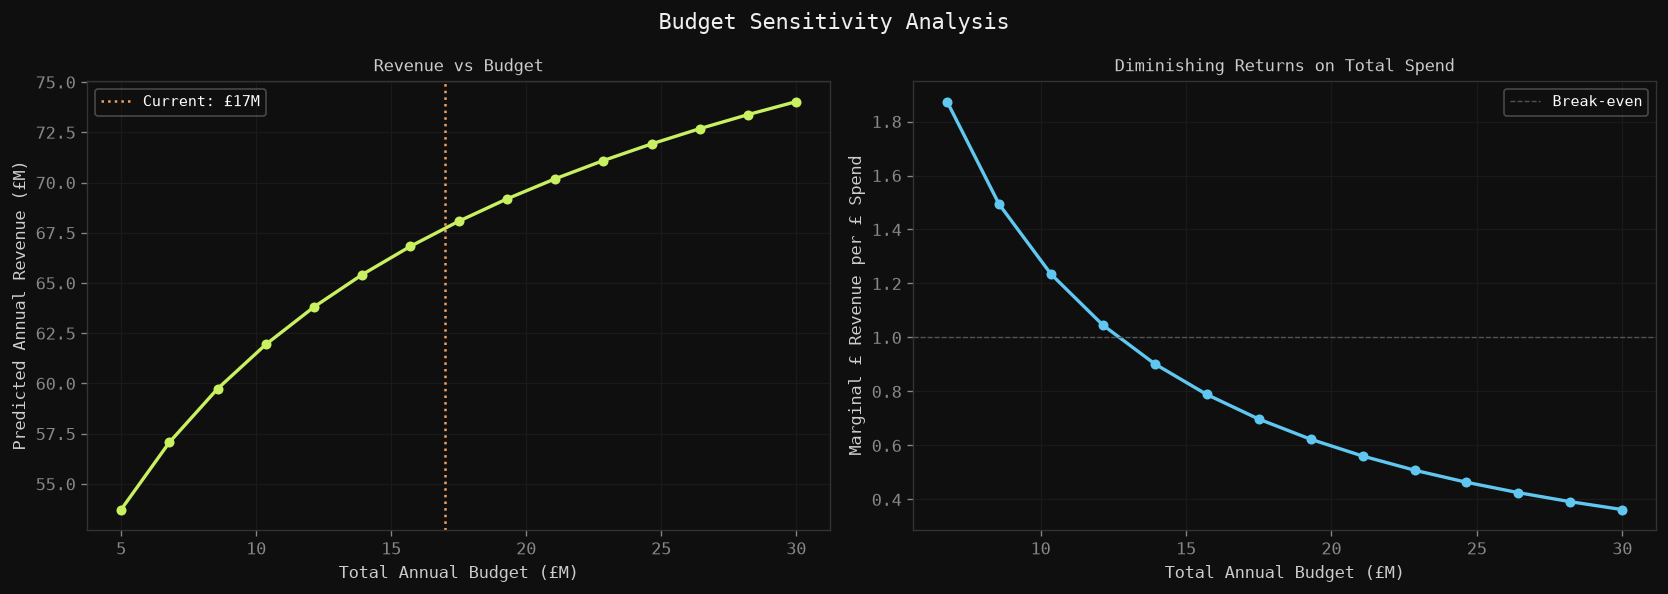

In [20]:
# How does optimal revenue scale with total budget?
budgets = np.linspace(5_000_000, 30_000_000, 15)
revenues = []

for b in budgets:
    opt = model.optimise_budget(b, train_df, n_weeks=52)
    revenues.append(opt['expected_revenue'])

marginal_returns = np.diff(revenues) / np.diff(budgets)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Budget Sensitivity Analysis', color='#EEE', fontsize=13)

axes[0].plot(budgets / 1e6, np.array(revenues) / 1e6, color='#C8F060', linewidth=2, marker='o', markersize=5)
axes[0].set_xlabel('Total Annual Budget (£M)', color='#CCC')
axes[0].set_ylabel('Predicted Annual Revenue (£M)', color='#CCC')
axes[0].set_title('Revenue vs Budget', color='#CCC', fontsize=10)
axes[0].axvline(total_budget / 1e6, color='#F0A060', linestyle=':', linewidth=1.5, label=f'Current: £{total_budget/1e6:.0f}M')
axes[0].legend(fontsize=9, framealpha=0.3)
axes[0].grid(True)

axes[1].plot(budgets[1:] / 1e6, marginal_returns, color='#60C8F0', linewidth=2, marker='o', markersize=5)
axes[1].axhline(1.0, color='#555', linestyle='--', linewidth=0.8, label='Break-even')
axes[1].set_xlabel('Total Annual Budget (£M)', color='#CCC')
axes[1].set_ylabel('Marginal £ Revenue per £ Spend', color='#CCC')
axes[1].set_title('Diminishing Returns on Total Spend', color='#CCC', fontsize=10)
axes[1].legend(fontsize=9, framealpha=0.3)
axes[1].grid(True)

plt.tight_layout()
plt.show()